# Tallinn Livability Score — Data Prep Notebook 1: Clean, Clip, Join

This notebook does three things, in order:

1. **Load** residential apartment buildings for Tallinn — already joined to
   Ehitisregister (EHR) attributes, including energy class, by Maa- ja
   Ruumiamet's own `etak_ehr_hooned` WFS layer. No manual ID join needed;
   that work is done upstream by the data owner.
2. **Filter** the ETAK GeoPackage down to the green/blue space layers we
   need (vegetation, open land, sea, lakes, rivers), and **clip** both
   layers to `aoi.geojson` (your Tallinn boundary).
3. **Save** both layers into one clean output GeoPackage.

Output: `tallinn_livability_base.gpkg` with layers `buildings` (residential
apartment buildings only, energy class attached) and `green_blue_space`,
ready for the next notebook (proximity/distance calculations with OSRM).

---
### Where the buildings data comes from

Earlier versions of this notebook tried joining the 892MB
`Hoone energia märgised.csv` EHR export onto ETAK's building layer by ID —
that join never matched (two unrelated internal ID spaces; `ehr_gid` vs
`ehit_id`). Instead, we now pull from Maa-amet's official pre-joined
`etak_ehr_hooned` WFS layer
(https://gsavalik.envir.ee/geoserver/etak_tuletis/wfs), which already
combines ETAK building geometry with EHR attributes (energy class, address,
`ehr_gid`, usage-purpose code). We filtered it server-side to
`kaos_kood_peamine = '11222'` ("Muu kolme või enama korteriga elamu" —
apartment buildings with 3+ units) and downloaded the result for Tallinn
(7,842 buildings, ~49% with energy class populated) into
`data/tallinn_apartment_buildings_ehr.gpkg`. A Harju-county-wide version
(10,149 buildings) is also saved as `data/harju_apartment_buildings_ehr.gpkg`
if you need the wider extent later.

### ⚠️ Before running: edit the CONFIG cell below

Confirm `DATA_DIR`, file paths, and `GREEN_BLUE_LAYERS` match your actual
files.


## 1. Imports

In [1]:
import geopandas as gpd
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)


## 2. CONFIG — edit these paths and names to match your actual files

- `DATA_DIR` — folder containing all your downloaded datasets.
- `ETAK_GPKG` — the ETAK GeoPackage filename (only used for the green/blue
  space layers now — buildings come from a separate pre-joined file).
- `AOI_PATH` — your `aoi.geojson` Tallinn boundary file.
- `APARTMENT_BUILDINGS_GPKG` — the pre-joined residential apartment
  buildings layer (geometry + EHR attributes, including energy class)
  downloaded from Maa-amet's `etak_ehr_hooned` WFS service.
- `GREEN_BLUE_LAYERS` — the ETAK layers we decided were relevant for
  green/blue space (vegetation, open land, sea, lakes, rivers).
- `ENERGY_COL` — the energy-class column name on the buildings layer.


In [2]:
DATA_DIR = Path("./data")          # <-- change if your data lives elsewhere

ETAK_GPKG   = DATA_DIR / "ETAK_EESTI_GPKG.gpkg"     # <-- used only for green/blue space layers
AOI_PATH    = DATA_DIR / "aoi.geojson"              # <-- Tallinn boundary

# Residential apartment buildings (kaos_kood_peamine == "11222"), pre-joined
# to EHR attributes (energy class, address, ehr_gid) by Maa-amet's official
# etak_ehr_hooned WFS layer — see the top-of-notebook note for how this was
# downloaded. Swap in the Harju county file below if you need the wider area.
APARTMENT_BUILDINGS_GPKG   = DATA_DIR / "tallinn_apartment_buildings_ehr.gpkg"
# APARTMENT_BUILDINGS_GPKG = DATA_DIR / "harju_apartment_buildings_ehr.gpkg"  # <-- county-wide alternative
APARTMENT_BUILDINGS_LAYER  = "apartment_buildings"
ENERGY_COL                 = "energiaklass"   # values like 'A'..'H'; ~49% populated, rest = no certificate on file

OUTPUT_GPKG = DATA_DIR / "tallinn_livability_base.gpkg"

# ETAK layers we decided were relevant for green/blue space (edit freely)
GREEN_BLUE_LAYERS = [
    "E_305_puittaimestik_a",   # woody vegetation (area)
    "E_304_lage_a",            # open land (parks/meadows)
    "E_201_meri_a",            # sea
    "E_202_seisuveekogu_a",    # lakes / standing water
    "E_203_vooluveekogu_a",    # rivers / streams
]


## 3. Inspect the GeoPackage — confirm layer names

Run this to list every layer actually present in your GeoPackage, so you can
confirm `GREEN_BLUE_LAYERS` above is spelled exactly right (Estonian layer
names are easy to typo). Buildings no longer come from this file — see
section 4.


In [3]:
import fiona
available_layers = fiona.listlayers(ETAK_GPKG)
print(f"{len(available_layers)} layers found in {ETAK_GPKG.name}:\n")
for lyr in available_layers:
    print(" -", lyr)


41 layers found in ETAK_EESTI_GPKG.gpkg:

 - E_101_kivi_p
 - E_102_nolv_j
 - E_103_pinnavorm_j
 - E_103_pinnavorm_p
 - E_201_meri_a
 - E_202_seisuveekogu_a
 - E_202_seisuveekogu_p
 - E_203_vooluveekogu_a
 - E_203_vooluveekogu_j
 - E_204_kaldajoon_j
 - E_205_hudrotehniline_rajatis_j
 - E_206_truup_j
 - E_301_muu_kolvik_a
 - E_301_muu_kolvik_ka
 - E_301_muu_kolvik_p
 - E_302_ou_a
 - E_303_haritav_maa_a
 - E_304_lage_a
 - E_305_puittaimestik_a
 - E_305_puittaimestik_j
 - E_305_puittaimestik_p
 - E_306_margala_a
 - E_306_margala_ka
 - E_307_turbavali_a
 - E_401_hoone_ka
 - E_402_korgrajatis_p
 - E_403_muu_rajatis_ka
 - E_403_muu_rajatis_p
 - E_404_maaalune_hoone_ka
 - E_405_piire_j
 - E_501_tee_a
 - E_501_tee_j
 - E_502_roobastee_j
 - E_503_siht_j
 - E_505_liikluskorralduslik_rajatis_ka
 - E_505_liikluskorralduslik_rajatis_j
 - E_601_elektriliin_j
 - E_602_tehnopaigaldis_p
 - E_603_torujuhe_j
 - Alusdokument
 - Tootmisaeg


## 4. Inspect the apartment buildings layer — confirm columns

Quick look at `APARTMENT_BUILDINGS_GPKG` before using it downstream — confirms
`ENERGY_COL` is right and shows how much of the data is actually populated
(not every building has an energy certificate on file).


In [4]:
buildings_preview = gpd.read_file(APARTMENT_BUILDINGS_GPKG, layer=APARTMENT_BUILDINGS_LAYER, rows=5)
print("Columns:", list(buildings_preview.columns))
print()
buildings_preview[["ehr_gid", "ads_lahiaadress", "kaos_nimetus_peamine", ENERGY_COL, "max_korruste_arv"]]


Columns: ['id', 'etak_id', 'ehr_gid', 'kood', 'kood_tekst', 'tyyp', 'tyyp_tekst', 'markused', 'ads_oid', 'ads_lahiaadress', 'taisaadress', 'korgus_m', 'nimetus', 'esmane_kasutus', 'max_korruste_arv', 'min_korruste_arv', 'korgus', 'ehitisalune_pind', 'ehitisalune_maap_pind', 'suletud_netopind', 'kaos_kood_peamine', 'kaos_nimetus_peamine', 'kaos_kood', 'kaos_nimetus', 'seisund', 'energiaklass', 'ehr_url', 'muutmisaeg', 'geometry']



,ehr_gid,ads_lahiaadress,kaos_nimetus_peamine,energiaklass,max_korruste_arv
0,101010291,Varju tee 1,11222 Muu kolme või enama korteriga elamu,NaN,1.0
1,101015971,Paldiski mnt 42,Muu kolme või enama korteriga elamu,D,2.0
2,120262102,Kõlviku tee 11,Muu kolme või enama korteriga elamu,NaN,3.0
3,101034567,Sepa tn 3,11222 Muu kolme või enama korteriga elamu,NaN,2.0
4,121282970-2,Kloostrimetsa tee 56a/2,Muu kolme või enama korteriga elamu,B,3.0


## 5. Load the AOI (Tallinn boundary)

Everything downstream gets clipped to this. We also grab its CRS (coordinate
reference system) so we can make sure every other layer matches before
clipping — mismatched CRSs are the #1 cause of "clip returns nothing" bugs.


AOI CRS: EPSG:4326
AOI bounds: [24.55017   59.3518076 24.9262831 59.5915769]


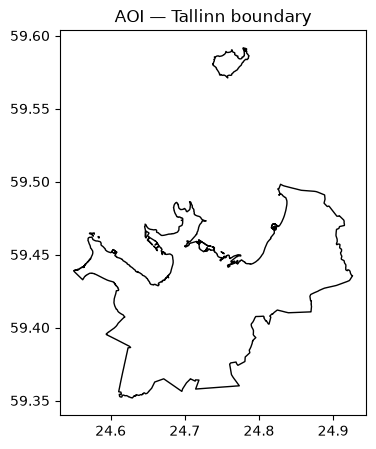

In [5]:
aoi = gpd.read_file(AOI_PATH)
print("AOI CRS:", aoi.crs)
print("AOI bounds:", aoi.total_bounds)

fig, ax = plt.subplots(figsize=(5, 5))
aoi.plot(ax=ax, edgecolor="black", facecolor="none")
ax.set_title("AOI — Tallinn boundary")
plt.show()


## 6. Load apartment buildings and clip to AOI

Loads the pre-joined residential apartment buildings layer, reprojects to
match the AOI's CRS if needed, and clips to the Tallinn boundary. No
attribute join happens here — energy class already arrived attached, from
Maa-amet's `etak_ehr_hooned` WFS layer.


Loaded 7,842 residential apartment buildings. CRS: EPSG:3301
With energiaklass populated: 3,807 (48.5%)
After clipping to Tallinn AOI: 7,842 buildings remain


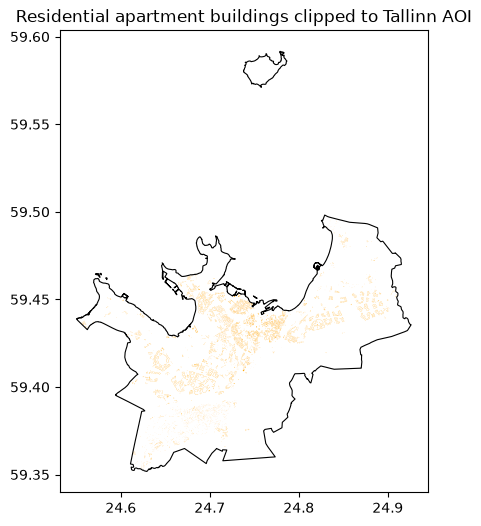

In [6]:
buildings = gpd.read_file(APARTMENT_BUILDINGS_GPKG, layer=APARTMENT_BUILDINGS_LAYER)
print(f"Loaded {len(buildings):,} residential apartment buildings. CRS: {buildings.crs}")
print(f"With {ENERGY_COL} populated: {buildings[ENERGY_COL].notna().sum():,} "
      f"({buildings[ENERGY_COL].notna().mean():.1%})")

if buildings.crs != aoi.crs:
    buildings = buildings.to_crs(aoi.crs)

buildings_clipped = gpd.clip(buildings, aoi)
print(f"After clipping to Tallinn AOI: {len(buildings_clipped):,} buildings remain")

fig, ax = plt.subplots(figsize=(6, 6))
buildings_clipped.plot(ax=ax, color="orange", edgecolor="none")
aoi.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Residential apartment buildings clipped to Tallinn AOI")
plt.show()


## 7. Load + combine green/blue space layers, clip to AOI

Each layer in `GREEN_BLUE_LAYERS` is loaded, tagged with a `space_type`
category (so you know which original layer each polygon came from), combined
into one GeoDataFrame, then clipped to the AOI in a single pass.


E_305_puittaimestik_a: 159,045 features
E_304_lage_a: 299,271 features
E_201_meri_a: 472 features
E_202_seisuveekogu_a: 122,050 features
E_203_vooluveekogu_a: 6,597 features

Combined green/blue space after clipping: 3,128 features


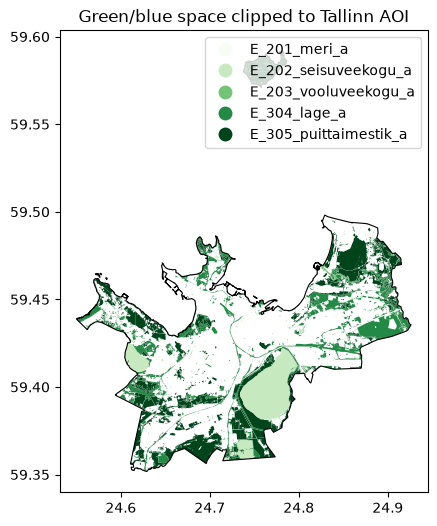

In [7]:
gb_frames = []
for layer_name in GREEN_BLUE_LAYERS:
    gdf = gpd.read_file(ETAK_GPKG, layer=layer_name)
    if gdf.crs != aoi.crs:
        gdf = gdf.to_crs(aoi.crs)
    gdf["space_type"] = layer_name
    gb_frames.append(gdf)
    print(f"{layer_name}: {len(gdf):,} features")

green_blue = pd.concat(gb_frames, ignore_index=True)
green_blue = gpd.GeoDataFrame(green_blue, geometry="geometry", crs=aoi.crs)

green_blue_clipped = gpd.clip(green_blue, aoi)
print(f"\nCombined green/blue space after clipping: {len(green_blue_clipped):,} features")

fig, ax = plt.subplots(figsize=(6, 6))
green_blue_clipped.plot(ax=ax, column="space_type", legend=True, cmap="Greens")
aoi.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Green/blue space clipped to Tallinn AOI")
plt.show()


## 8. Save the cleaned, clipped output

Both layers get written into one GeoPackage with descriptive layer names,
ready to feed into the next notebook (proximity/distance scoring with OSRM).


In [8]:
green_blue_final = green_blue_clipped.copy()

buildings_clipped.to_file(OUTPUT_GPKG, layer="buildings", driver="GPKG")
green_blue_final.to_file(OUTPUT_GPKG, layer="green_blue_space", driver="GPKG")

with_energy = buildings_clipped[ENERGY_COL].notna().sum()
print(f"Saved -> {OUTPUT_GPKG}")
print(f"  layer 'buildings': {len(buildings_clipped):,} residential apartment buildings, "
      f"{with_energy:,} ({with_energy/len(buildings_clipped):.1%}) with energy class")
print(f"  layer 'green_blue_space': {len(green_blue_final):,} features")


Saved -> data/tallinn_livability_base.gpkg
  layer 'buildings': 7,842 residential apartment buildings, 3,807 (48.5%) with energy class
  layer 'green_blue_space': 3,128 features


## Next steps

- Buildings without `energiaklass` (no certificate on file, ~51%) are still
  kept in the output — decide in the scoring notebook whether to drop them,
  impute a value, or treat "missing energy data" as its own category.
- Need the wider Harju county extent instead of Tallinn only? Point
  `APARTMENT_BUILDINGS_GPKG` at `data/harju_apartment_buildings_ehr.gpkg`
  and re-run from section 6 — note the green/blue space clip will still
  restrict to the Tallinn AOI unless you also swap in a Harju boundary.
- Next notebook: set up OSRM locally and compute network walking distances
  from each building to bus stops, groceries, gyms, and green/blue space
  edges — feeding into the normalization + scoring step.
